# Phase 6 — Predictive Analytics: Monthly Revenue Forecasting

## 1. Objective and business rules
Prepare and validate monthly revenue and exactly three lag features; **no model training, prediction, baseline, or backtesting**.

- Read only `data/processed/Orders_clean.csv` and `data/processed/OrderItems_clean.csv`.
- Keep `OrderStatus == "Completed"`; inner join on `OrderID`.
- Use item-level `UnitPrice`: `SalesAmount = Quantity * UnitPrice * (1 - DiscountPercent / 100)`.
- Aggregate by `OrderDate`, January 2024 through December 2025 inclusive, without rounding.
- Preserve the original monthly series; remove unavailable lag rows only from the feature/target table.
- Use `Decimal` values parsed directly from CSV text to preserve decimal precision. No float conversion or rounding is performed. Conversion for scikit-learn is deferred to a later phase.
- Report reference mismatches without changing the data or calculation rules. No CSV files are written.

## 2. Load the clean data
Resolve the project root from the working directory or its ancestors. When Jupyter runs elsewhere, use the explicit project location below (editable if the project moves). All input paths are relative to the resolved root.

In [1]:
from pathlib import Path
from decimal import Decimal, getcontext
import pandas as pd
from IPython.display import display

getcontext().prec = 40
PROJECT_ROOT_FALLBACK = Path(r"C:\Users\meshal\Desktop\RetailSalesAnalytics")
RELATIVE_INPUTS = (
    Path("data/processed/Orders_clean.csv"),
    Path("data/processed/OrderItems_clean.csv"),
)
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, PROJECT_ROOT_FALLBACK]
PROJECT_ROOT = next(
    (p for p in candidates if all((p / f).is_file() for f in RELATIVE_INPUTS)),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT_FALLBACK to the RetailSalesAnalytics project root.")
print("Project root:", PROJECT_ROOT)

orders = pd.read_csv(PROJECT_ROOT / RELATIVE_INPUTS[0], dtype="string")
items = pd.read_csv(PROJECT_ROOT / RELATIVE_INPUTS[1], dtype="string")
order_columns = ["OrderID", "OrderDate", "OrderStatus"]
item_columns = ["OrderItemID", "OrderID", "Quantity", "UnitPrice", "DiscountPercent"]
assert set(order_columns).issubset(orders.columns)
assert set(item_columns).issubset(items.columns)
assert not orders[order_columns].isna().any().any(), "Missing required order values"
assert not items[item_columns].isna().any().any(), "Missing required item values"
assert orders["OrderID"].is_unique, "Duplicate OrderID in Orders"
assert items["OrderItemID"].is_unique, "Duplicate OrderItemID"
assert items["OrderID"].isin(orders["OrderID"]).all(), "Orphan item rows"
orders["OrderDate"] = pd.to_datetime(orders["OrderDate"], errors="raise")
for column in ["Quantity", "UnitPrice", "DiscountPercent"]:
    items[column] = items[column].map(Decimal)
    assert items[column].map(lambda value: value.is_finite()).all()
print(f"Loaded orders: {len(orders):,}; order items: {len(items):,}")

Project root: C:\Users\meshal\Desktop\RetailSalesAnalytics
Loaded orders: 5,000; order items: 13,346


## 3. Calculate monthly revenue
The end boundary is exclusive (`2026-01-01`), so all of December 2025 is included. Missing months are reported as a failed validation rather than silently filled with zero. Completed orders are counted once from Orders, not from joined item rows.

In [2]:
start = pd.Timestamp("2024-01-01")
end_exclusive = pd.Timestamp("2026-01-01")
completed_orders = orders.loc[
    orders["OrderStatus"].eq("Completed")
    & orders["OrderDate"].ge(start)
    & orders["OrderDate"].lt(end_exclusive),
    order_columns,
].copy()
completed_order_count = completed_orders["OrderID"].nunique()
joined = completed_orders.merge(
    items[item_columns], on="OrderID", how="inner", validate="one_to_many"
)
assert set(joined["OrderID"]) == set(completed_orders["OrderID"]), "Completed orders without items"
joined["SalesAmount"] = (
    joined["Quantity"] * joined["UnitPrice"]
    * (Decimal("1") - joined["DiscountPercent"] / Decimal("100"))
)
joined["Month"] = joined["OrderDate"].dt.to_period("M").dt.to_timestamp()
def exact_sum(values):
    return sum(values, Decimal("0"))

monthly_revenue = (
    joined.groupby("Month", sort=True)["SalesAmount"]
    .agg(exact_sum).rename("Revenue").to_frame()
)
expected_months = pd.date_range(start, "2025-12-01", freq="MS", name="Month")
missing_months = expected_months.difference(monthly_revenue.index)
extra_months = monthly_revenue.index.difference(expected_months)
print("Number of months:", len(monthly_revenue))
print("Missing months:", missing_months.tolist())
print("Unexpected months:", extra_months.tolist())
assert monthly_revenue.index.equals(expected_months), "Expected exactly 24 consecutive months"
assert monthly_revenue.index.is_unique and monthly_revenue.index.is_monotonic_increasing
print("First five months")
display(monthly_revenue.head())
print("Last five months")
display(monthly_revenue.tail())
monthly_original = monthly_revenue.copy(deep=True)

Number of months: 24
Missing months: []
Unexpected months: []
First five months
Last five months


,Revenue
Month,
2024-01-01,1225434.9035
2024-02-01,1056767.4065
2024-03-01,1035761.5575
2024-04-01,1123892.7400
2024-05-01,1124008.8300


,Revenue
Month,
2025-08-01,1363451.7605
2025-09-01,1145622.9130
2025-10-01,897984.2175
2025-11-01,1183186.7845
2025-12-01,1096146.0100


## 4. Validate reference metrics
Revenue tolerance is an absolute `0.000001` (one millionth), with no relative tolerance. The order count must match exactly. Differences retain their full decimal precision; any mismatch is reported and does not trigger data adjustment.

In [3]:
tolerance = Decimal("0.000001")
actuals = {
    "Total Revenue": exact_sum(monthly_revenue["Revenue"]),
    "2024 Revenue": exact_sum(monthly_revenue.loc[monthly_revenue.index.year == 2024, "Revenue"]),
    "2025 Revenue": exact_sum(monthly_revenue.loc[monthly_revenue.index.year == 2025, "Revenue"]),
    "Completed Orders": Decimal(int(completed_order_count)),
}
references = {
    "Total Revenue": Decimal("25746272.0155"),
    "2024 Revenue": Decimal("12864362.4090"),
    "2025 Revenue": Decimal("12881909.6065"),
    "Completed Orders": Decimal("4038"),
}
reference_checks = pd.DataFrame([
    {
        "Metric": metric, "Actual": actuals[metric], "Expected": expected,
        "Difference": actuals[metric] - expected,
        "Tolerance": Decimal("0") if metric == "Completed Orders" else tolerance,
        "Passed": abs(actuals[metric] - expected) <= (Decimal("0") if metric == "Completed Orders" else tolerance),
    }
    for metric, expected in references.items()
]).set_index("Metric")
display(reference_checks)
reference_passed = bool(reference_checks["Passed"].all())
print("Reference validation:", "PASS" if reference_passed else "MISMATCH — investigate without altering data or rules")
assert exact_sum(joined["SalesAmount"]) == actuals["Total Revenue"]

Reference validation: PASS


,Actual,Expected,Difference,Tolerance,Passed
Metric,,,,,
Total Revenue,25746272.0155,25746272.0155,0.0000,0.000001,True
2024 Revenue,12864362.4090,12864362.4090,0.0000,0.000001,True
2025 Revenue,12881909.6065,12881909.6065,0.0000,0.000001,True
Completed Orders,4038,4038,0,0,True


## 5. Prepare Features and Target
Each row targets its own month. `lag_1`, `lag_2`, and `lag_3` contain revenue from exactly one, two, and three calendar months earlier. The 24-month series is retained. Only rows with unavailable lag values are dropped from the training table.

In [4]:
lag_columns = ["lag_1", "lag_2", "lag_3"]
feature_target_all = pd.DataFrame({"TargetMonth": monthly_revenue.index})
for offset in (1, 2, 3):
    feature_target_all[f"lag_{offset}"] = monthly_revenue["Revenue"].shift(offset).to_numpy()
feature_target_all["Target"] = monthly_revenue["Revenue"].to_numpy()
print("Missing values before dropping unavailable lag rows")
display(feature_target_all.isna().sum().to_frame("Missing"))
feature_target = feature_target_all.dropna(subset=lag_columns).reset_index(drop=True).copy()
print("First five valid rows")
display(feature_target.head())
print("Last five valid rows")
display(feature_target.tail())
print("Valid rows:", len(feature_target))
print("Target period:", feature_target["TargetMonth"].min(), "to", feature_target["TargetMonth"].max())

Missing values before dropping unavailable lag rows
First five valid rows
Last five valid rows
Valid rows: 21
Target period: 2024-04-01 00:00:00 to 2025-12-01 00:00:00


,Missing
TargetMonth,0
lag_1,1
lag_2,2
lag_3,3
Target,0


,TargetMonth,lag_1,lag_2,lag_3,Target
0,2024-04-01,1035761.5575,1056767.4065,1225434.9035,1123892.7400
1,2024-05-01,1123892.7400,1035761.5575,1056767.4065,1124008.8300
2,2024-06-01,1124008.8300,1123892.7400,1035761.5575,1038212.2460
3,2024-07-01,1038212.2460,1124008.8300,1123892.7400,986330.5250
4,2024-08-01,986330.5250,1038212.2460,1124008.8300,1145439.2180


,TargetMonth,lag_1,lag_2,lag_3,Target
16,2025-08-01,1154054.6840,960893.0710,1109284.1050,1363451.7605
17,2025-09-01,1363451.7605,1154054.6840,960893.0710,1145622.9130
18,2025-10-01,1145622.9130,1363451.7605,1154054.6840,897984.2175
19,2025-11-01,897984.2175,1145622.9130,1363451.7605,1183186.7845
20,2025-12-01,1183186.7845,897984.2175,1145622.9130,1096146.0100


## 6. Forecast-table quality checks
For **every row and every lag**, independently calculate the source calendar month, require it to precede the target month, and match the value against the original monthly series. This checks all 63 lag values. Source dates are used only for validation and are not additional features.

This table uses observed prior-month revenue. A later modeling phase must define the forecast horizon and chronological evaluation protocol; this preparation alone does not establish leakage-free multi-step evaluation.

In [5]:
assert list(feature_target.columns) == ["TargetMonth", "lag_1", "lag_2", "lag_3", "Target"]
assert len(feature_target) == 21
assert pd.DatetimeIndex(feature_target["TargetMonth"]).equals(pd.date_range("2024-04-01", "2025-12-01", freq="MS"))
assert feature_target["TargetMonth"].is_unique
assert feature_target["TargetMonth"].is_monotonic_increasing
print("Missing values in monthly series")
display(monthly_revenue.isna().sum().to_frame("Missing"))
print("Missing values in final feature/target table")
display(feature_target.isna().sum().to_frame("Missing"))
assert not monthly_revenue.isna().any().any()
assert not feature_target.isna().any().any()
checked_lags = 0
for row in feature_target.itertuples(index=False):
    assert row.Target == monthly_original.loc[row.TargetMonth, "Revenue"]
    for offset in (1, 2, 3):
        source_month = row.TargetMonth - pd.DateOffset(months=offset)
        assert source_month < row.TargetMonth, "Current/future month leakage"
        assert source_month in monthly_original.index
        assert getattr(row, f"lag_{offset}") == monthly_original.loc[source_month, "Revenue"], "Lag value mismatch"
        checked_lags += 1
pd.testing.assert_frame_equal(monthly_revenue, monthly_original)
assert all(isinstance(value, Decimal) and value.is_finite()
           for column in [*lag_columns, "Target"] for value in feature_target[column])
print(f"PASS: {checked_lags} lag values match strictly earlier calendar months.")
print("PASS: 24 original months preserved; 21 complete rows, April 2024–December 2025.")
print("Reference metrics:", "PASS" if reference_passed else "MISMATCH (see section 4)")
print("Preparation only: no model, baseline, backtesting, or CSV export.")

Missing values in monthly series
Missing values in final feature/target table
PASS: 63 lag values match strictly earlier calendar months.
PASS: 24 original months preserved; 21 complete rows, April 2024–December 2025.
Reference metrics: PASS
Preparation only: no model, baseline, backtesting, or CSV export.


,Missing
Revenue,0


,Missing
TargetMonth,0
lag_1,0
lag_2,0
lag_3,0
Target,0


## 7. Task 2: Naive baseline and backtesting protocol
Evaluate six **one-month-ahead** forecasts for July-December 2025 with expanding observed history. At each origin, retain every month from January 2024 through the previous month. July uses June actual revenue; August uses July actual revenue after July ends. This is not a six-month forecast made entirely in June.

The fixed rule is `BaselinePrediction = lag_1`. There is no training or retraining, and no machine-learning model. Read the target actual only after producing its prediction, for scoring. The preceding sections and outputs remain the unchanged record of Task 1.

In [6]:
test_months = pd.date_range("2025-07-01", "2025-12-01", freq="MS")
monthly_before_baseline = monthly_revenue.copy(deep=True)
features_before_baseline = feature_target.copy(deep=True)
references_before_baseline = reference_checks.copy(deep=True)
backtest_rows, provenance_rows = [], []
for target_month in test_months:
    available_history = monthly_revenue.loc[monthly_revenue.index < target_month, "Revenue"]
    previous_month = target_month - pd.DateOffset(months=1)
    assert available_history.index.equals(pd.date_range("2024-01-01", previous_month, freq="MS"))
    assert (available_history.index < target_month).all()
    assert available_history.index[-1] == previous_month
    baseline_prediction = available_history.iloc[-1]
    # Outcome is accessed only after the prediction, solely for evaluation.
    actual_revenue = monthly_revenue.loc[target_month, "Revenue"]
    error = actual_revenue - baseline_prediction
    backtest_rows.append({"TargetMonth": target_month,
        "ActualRevenue": actual_revenue, "BaselinePrediction": baseline_prediction,
        "Error": error, "AbsoluteError": abs(error), "SquaredError": error ** 2})
    provenance_rows.append({"TargetMonth": target_month,
        "HistoryStart": available_history.index[0], "HistoryEnd": available_history.index[-1],
        "HistoryMonths": len(available_history), "PredictionSourceMonth": previous_month})
backtest_results = pd.DataFrame(backtest_rows)
backtest_provenance = pd.DataFrame(provenance_rows)
display(backtest_provenance)

,TargetMonth,HistoryStart,HistoryEnd,HistoryMonths,PredictionSourceMonth
0,2025-07-01,2024-01-01,2025-06-01,18,2025-06-01
1,2025-08-01,2024-01-01,2025-07-01,19,2025-07-01
2,2025-09-01,2024-01-01,2025-08-01,20,2025-08-01
3,2025-10-01,2024-01-01,2025-09-01,21,2025-09-01
4,2025-11-01,2024-01-01,2025-10-01,22,2025-10-01
5,2025-12-01,2024-01-01,2025-11-01,23,2025-11-01


## 8. Results and performance metrics
`Error = ActualRevenue - BaselinePrediction`. Negative error means overprediction; positive error means underprediction. Revenue and errors are in SAR; squared errors are in SAR squared.

MAE is the mean absolute error and RMSE is the square root of the mean squared error across all six months. Calculations use unrounded `Decimal` values with the existing 40-digit precision. Division and square root use that context. Two-decimal formatting is applied only to a display copy and printed metrics, never to scoring inputs.

In [7]:
backtest_display = backtest_results.copy(deep=True)
backtest_display["TargetMonth"] = backtest_display["TargetMonth"].dt.strftime("%Y-%m")
for column in ["ActualRevenue", "BaselinePrediction", "Error", "AbsoluteError", "SquaredError"]:
    backtest_display[column] = backtest_results[column].map(lambda value: f"{value:,.2f}")
display(backtest_display)
test_count = Decimal(len(backtest_results))
baseline_mae = exact_sum(backtest_results["AbsoluteError"]) / test_count
baseline_mse = exact_sum(backtest_results["SquaredError"]) / test_count
baseline_rmse = baseline_mse.sqrt()
worst_error = max(backtest_results["AbsoluteError"])
worst_months = backtest_results.loc[backtest_results["AbsoluteError"].eq(worst_error), "TargetMonth"]
overprediction_count = int((backtest_results["Error"] < Decimal("0")).sum())
underprediction_count = int((backtest_results["Error"] > Decimal("0")).sum())
exact_prediction_count = int((backtest_results["Error"] == Decimal("0")).sum())
print(f"MAE: {baseline_mae:,.2f} SAR")
print(f"RMSE: {baseline_rmse:,.2f} SAR")
print("Largest absolute error month(s):", ", ".join(worst_months.dt.strftime("%Y-%m")))
print(f"Largest absolute error: {worst_error:,.2f} SAR")
print("Overprediction months:", overprediction_count)
print("Underprediction months:", underprediction_count)
print("Exact prediction months:", exact_prediction_count)

MAE: 206,711.60 SAR
RMSE: 215,580.41 SAR
Largest absolute error month(s): 2025-11
Largest absolute error: 285,202.57 SAR
Overprediction months: 3
Underprediction months: 3
Exact prediction months: 0


,TargetMonth,ActualRevenue,BaselinePrediction,Error,AbsoluteError,SquaredError
0,2025-07,"1,154,054.68","960,893.07","193,161.61","193,161.61","37,311,408,736.76"
1,2025-08,"1,363,451.76","1,154,054.68","209,397.08","209,397.08","43,847,135,646.75"
2,2025-09,"1,145,622.91","1,363,451.76","-217,828.85","217,828.85","47,449,406,803.18"
3,2025-10,"897,984.22","1,145,622.91","-247,638.70","247,638.70","61,324,923,508.94"
4,2025-11,"1,183,186.78","897,984.22","285,202.57","285,202.57","81,340,504,223.39"
5,2025-12,"1,096,146.01","1,183,186.78","-87,040.77","87,040.77","7,576,096,425.56"


## 9. Actual revenue versus naive baseline chart
Float conversion is restricted to plotting coordinates. The figure is embedded in this notebook; no external image or CSV is written.

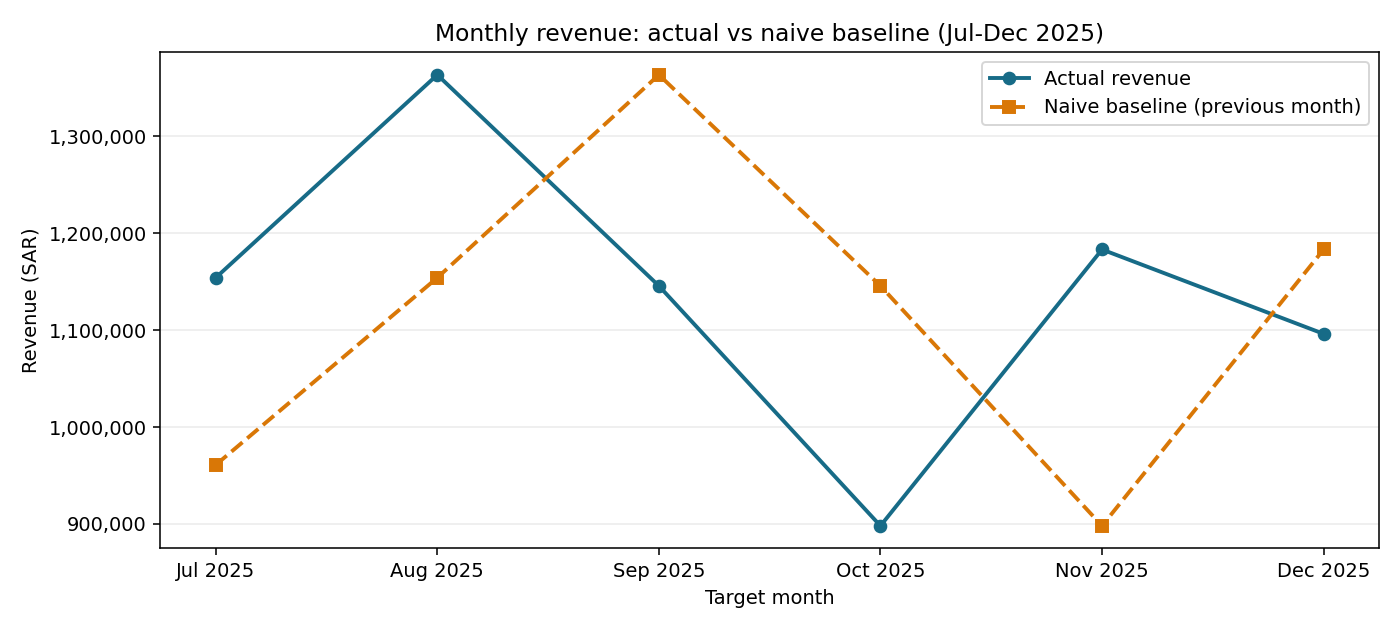

In [8]:
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.ticker import FuncFormatter
from io import BytesIO
from IPython.display import Image

fig = Figure(figsize=(10, 4.5))
canvas = FigureCanvasAgg(fig)
ax = fig.subplots()
month_labels = backtest_results["TargetMonth"].dt.strftime("%b %Y")
ax.plot(month_labels, backtest_results["ActualRevenue"].map(float),
        marker="o", linewidth=2, label="Actual revenue", color="#176b87")
ax.plot(month_labels, backtest_results["BaselinePrediction"].map(float),
        marker="s", linestyle="--", linewidth=2, label="Naive baseline (previous month)", color="#d97706")
ax.set(title="Monthly revenue: actual vs naive baseline (Jul-Dec 2025)",
       xlabel="Target month", ylabel="Revenue (SAR)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
with BytesIO() as chart_buffer:
    fig.savefig(chart_buffer, format="png", dpi=140)
    display(Image(data=chart_buffer.getvalue()))

## 10. Backtesting quality checks
Check the exact six-month calendar, order, completeness, equality with approved `lag_1`, and forecast source dates. Independently reproduce each forecast using a series truncated strictly before its target month. All prior observations are retained: the six expanding histories contain 18 through 23 months.

Verify that the original series, Features/Target table, and reference results remain unchanged. No model training follows this evaluation.

In [9]:
approved_targets = feature_target.set_index("TargetMonth")
quality_checks = {
    "Exactly six months": len(backtest_results) == 6,
    "Exact ordered July-December 2025 calendar": pd.DatetimeIndex(backtest_results["TargetMonth"]).equals(test_months),
    "Unique months": backtest_results["TargetMonth"].is_unique,
    "No missing values": not backtest_results.isna().any().any() and not backtest_provenance.isna().any().any(),
    "Finite Decimal values": all(isinstance(v, Decimal) and v.is_finite()
        for col in ["ActualRevenue", "BaselinePrediction", "Error", "AbsoluteError", "SquaredError"]
        for v in backtest_results[col]),
    "All preceding months retained": backtest_provenance["HistoryMonths"].tolist() == [18, 19, 20, 21, 22, 23],
    "Baseline equals lag_1": all(r.BaselinePrediction == approved_targets.loc[r.TargetMonth, "lag_1"]
        for r in backtest_results.itertuples(index=False)),
    "Actual equals approved Target": all(r.ActualRevenue == approved_targets.loc[r.TargetMonth, "Target"]
        for r in backtest_results.itertuples(index=False)),
    "Source is strictly the previous month": all(
        r.PredictionSourceMonth == r.TargetMonth - pd.DateOffset(months=1)
        and r.HistoryEnd == r.PredictionSourceMonth < r.TargetMonth
        for r in backtest_provenance.itertuples(index=False)),
    "Predictions reproducible without target or future observations": all(
        r.BaselinePrediction == monthly_revenue.loc[monthly_revenue.index < r.TargetMonth, "Revenue"].iloc[-1]
        for r in backtest_results.itertuples(index=False)),
    "Direction counts total six": overprediction_count + underprediction_count + exact_prediction_count == 6,
}
pd.testing.assert_frame_equal(monthly_revenue, monthly_before_baseline)
pd.testing.assert_frame_equal(feature_target, features_before_baseline)
pd.testing.assert_frame_equal(reference_checks, references_before_baseline)
quality_checks["Task 1 data and reference results unchanged"] = True
quality_report = pd.Series(quality_checks, name="Passed").to_frame()
display(quality_report)
assert all(quality_checks.values()), "Backtesting quality check failed"
print("PASS: all baseline/backtesting checks passed. Stop before ML training.")

PASS: all baseline/backtesting checks passed. Stop before ML training.


,Passed
Exactly six months,True
Exact ordered July-December 2025 calendar,True
Unique months,True
No missing values,True
Finite Decimal values,True
All preceding months retained,True
Baseline equals lag_1,True
Actual equals approved Target,True
Source is strictly the previous month,True
Predictions reproducible without target or future observations,True


## 11. Task 3: Ridge one-step-ahead evaluation
Use only `lag_1`, `lag_2`, and `lag_3` to predict `Target`, with fixed `Ridge(alpha=1.0)` and `StandardScaler` in one fresh `Pipeline` per origin. Test July-December 2025 using all eligible earlier target rows: 15, 16, 17, 18, 19, and 20 training rows respectively.

July's actual may enter August's history after July ends. This is one-step-ahead evaluation, not a six-month forecast issued in June. No random split, tuning, extra feature, alternative model, or 2026 forecast is performed. Earlier sections/outputs remain the record of Tasks 1 and 2.

Scikit-learn receives separate float64 copies; original Decimal tables stay unchanged. The target month's actual is retrieved for scoring only after predict returns.

Reference: [scikit-learn guidance on pipelines and leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [10]:
import numpy as np
import sklearn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from unittest.mock import patch

print("scikit-learn version:", sklearn.__version__)
RIDGE_FEATURES = ["lag_1", "lag_2", "lag_3"]
RIDGE_ALPHA = 1.0
ridge_test_months = pd.DatetimeIndex(backtest_results["TargetMonth"])
assert ridge_test_months.equals(pd.date_range("2025-07-01", "2025-12-01", freq="MS"))
ridge_features_snapshot = feature_target.copy(deep=True)
ridge_monthly_snapshot = monthly_revenue.copy(deep=True)
ridge_baseline_snapshot = backtest_results.copy(deep=True)
ridge_reference_snapshot = reference_checks.copy(deep=True)
ridge_baseline_metrics_snapshot = (baseline_mae, baseline_rmse)
assert feature_target["TargetMonth"].is_unique
assert not feature_target[["TargetMonth", *RIDGE_FEATURES, "Target"]].isna().any().any()

def ridge_float64(frame):
    converted = frame.astype(np.float64)
    assert np.isfinite(converted.to_numpy()).all(), "NaN/Infinity after conversion"
    assert all(dtype == np.dtype("float64") for dtype in converted.dtypes)
    return converted

scikit-learn version: 1.7.2


## 12. Expanding-window fit and predict
Select training rows strictly before each test month. Fit a new pipeline once and predict exactly one row. Runtime wrappers count calls while executing the real fit/predict methods.

Check scaler sample counts, means and variances against only that round's training matrix, and verify prediction does not change scaler statistics. Verify all training and test lag values against their earlier source months. Audit columns are diagnostics, not features.

In [11]:
ridge_rows, ridge_audit_rows, ridge_pipelines, ridge_raw_predictions = [], [], [], []
for ridge_month in ridge_test_months:
    train_rows = feature_target.loc[feature_target["TargetMonth"] < ridge_month]
    test_features = feature_target.loc[
        feature_target["TargetMonth"].eq(ridge_month), ["TargetMonth", *RIDGE_FEATURES]
    ]
    assert len(test_features) == 1
    assert (train_rows["TargetMonth"] < ridge_month).all()
    assert pd.DatetimeIndex(train_rows["TargetMonth"]).equals(
        pd.date_range("2024-04-01", ridge_month - pd.DateOffset(months=1), freq="MS")
    )
    for lag_rows in (train_rows[["TargetMonth", *RIDGE_FEATURES]], test_features):
        for lag_row in lag_rows.itertuples(index=False):
            for offset in (1, 2, 3):
                source_month = lag_row.TargetMonth - pd.DateOffset(months=offset)
                assert source_month < lag_row.TargetMonth
                assert getattr(lag_row, f"lag_{offset}") == monthly_revenue.loc[source_month, "Revenue"]
    X_train = ridge_float64(train_rows[RIDGE_FEATURES])
    y_train = train_rows["Target"].to_numpy(dtype=np.float64)
    X_test = ridge_float64(test_features[RIDGE_FEATURES])
    assert y_train.dtype == np.float64 and np.isfinite(y_train).all()
    assert X_train.columns.tolist() == X_test.columns.tolist() == RIDGE_FEATURES
    ridge_pipeline = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=RIDGE_ALPHA))])
    assert not hasattr(ridge_pipeline.named_steps["scaler"], "mean_")
    assert not hasattr(ridge_pipeline.named_steps["ridge"], "coef_")
    assert all(ridge_pipeline is not prior for prior in ridge_pipelines)
    with patch.object(ridge_pipeline, "fit", wraps=ridge_pipeline.fit) as fit_call:
        ridge_pipeline.fit(X_train, y_train)
        fit_calls = fit_call.call_count
    assert fit_calls == 1
    scaler = ridge_pipeline.named_steps["scaler"]
    estimator = ridge_pipeline.named_steps["ridge"]
    assert scaler.n_samples_seen_ == len(train_rows)
    np.testing.assert_allclose(scaler.mean_, X_train.to_numpy().mean(axis=0), rtol=1e-12, atol=1e-9)
    np.testing.assert_allclose(scaler.var_, X_train.to_numpy().var(axis=0), rtol=1e-12, atol=1e-9)
    assert scaler.feature_names_in_.tolist() == RIDGE_FEATURES
    assert estimator.alpha == 1.0 and estimator.n_features_in_ == 3
    scaler_state = (scaler.mean_.copy(), scaler.var_.copy(), scaler.scale_.copy(), scaler.n_samples_seen_)
    with patch.object(ridge_pipeline, "predict", wraps=ridge_pipeline.predict) as predict_call:
        prediction_array = ridge_pipeline.predict(X_test)
        predict_calls = predict_call.call_count
        assert predict_call.call_args.args[0] is X_test
    assert predict_calls == 1 and prediction_array.shape == (1,)
    assert np.isfinite(prediction_array).all()
    for after, prior in zip((scaler.mean_, scaler.var_, scaler.scale_), scaler_state[:3]):
        np.testing.assert_array_equal(after, prior)
    assert scaler.n_samples_seen_ == scaler_state[3]
    ridge_raw_predictions.append(prediction_array.copy())
    ridge_pipelines.append(ridge_pipeline)
    # Preserve the returned binary64 value, without rounding to decimal places.
    ridge_prediction = Decimal.from_float(float(prediction_array[0]))
    # Access the test outcome only after predict has returned.
    actual_revenue = feature_target.loc[feature_target["TargetMonth"].eq(ridge_month), "Target"].iloc[0]
    ridge_error = actual_revenue - ridge_prediction
    ridge_rows.append({"TargetMonth": ridge_month, "TrainingRows": len(train_rows),
        "ActualRevenue": actual_revenue, "RidgePrediction": ridge_prediction,
        "Error": ridge_error, "AbsoluteError": abs(ridge_error), "SquaredError": ridge_error ** 2})
    ridge_audit_rows.append({"TargetMonth": ridge_month, "TrainingStart": train_rows["TargetMonth"].min(),
        "TrainingEnd": train_rows["TargetMonth"].max(), "TrainingRows": len(train_rows),
        "ScalerSamples": int(scaler.n_samples_seen_), "FitCalls": fit_calls, "PredictCalls": predict_calls,
        "Alpha": estimator.alpha, "TrainingOnlyScalerChecked": True, "LagSourcesChecked": True})
ridge_results = pd.DataFrame(ridge_rows)
ridge_audit = pd.DataFrame(ridge_audit_rows)
display(ridge_audit)

,TargetMonth,TrainingStart,TrainingEnd,TrainingRows,ScalerSamples,FitCalls,PredictCalls,Alpha,TrainingOnlyScalerChecked,LagSourcesChecked
0,2025-07-01,2024-04-01,2025-06-01,15,15,1,1,1.0,True,True
1,2025-08-01,2024-04-01,2025-07-01,16,16,1,1,1.0,True,True
2,2025-09-01,2024-04-01,2025-08-01,17,17,1,1,1.0,True,True
3,2025-10-01,2024-04-01,2025-09-01,18,18,1,1,1.0,True,True
4,2025-11-01,2024-04-01,2025-10-01,19,19,1,1,1.0,True,True
5,2025-12-01,2024-04-01,2025-11-01,20,20,1,1,1.0,True,True


## 13. Ridge results and preliminary comparison
Errors are ActualRevenue minus RidgePrediction. Values are in SAR, except squared errors in SAR squared. Decimal scoring uses the existing 40-digit context and original actuals. Predictions originate as float64; converting them to Decimal does not restore information lost in float64 conversion.

Only the display is rounded to two places. MAE/RMSE use unrounded errors. Difference = Baseline minus Ridge, so a positive difference indicates lower Ridge error. Improvement (%) = Difference / Baseline * 100; a negative percentage means Ridge is worse. Six test months provide a limited evaluation, not a tuning set or proof of general superiority.

In [12]:
ridge_display = ridge_results.copy(deep=True)
ridge_display["TargetMonth"] = ridge_display["TargetMonth"].dt.strftime("%Y-%m")
for column in ["ActualRevenue", "RidgePrediction", "Error", "AbsoluteError", "SquaredError"]:
    ridge_display[column] = ridge_results[column].map(lambda value: f"{value:,.2f}")
display(ridge_display)
ridge_mae = exact_sum(ridge_results["AbsoluteError"]) / Decimal(len(ridge_results))
ridge_rmse = (exact_sum(ridge_results["SquaredError"]) / Decimal(len(ridge_results))).sqrt()
comparison_results = pd.DataFrame([
    {"Metric": metric, "Baseline": base, "Ridge": candidate,
     "Difference (Baseline - Ridge)": base - candidate,
     "Improvement (%)": (base - candidate) / base * Decimal("100")}
    for metric, base, candidate in [("MAE", baseline_mae, ridge_mae), ("RMSE", baseline_rmse, ridge_rmse)]
]).set_index("Metric")
comparison_display = comparison_results.copy(deep=True)
for column in comparison_display.columns:
    comparison_display[column] = comparison_results[column].map(lambda value: f"{value:,.2f}")
display(comparison_display)
print(f"Ridge MAE: {ridge_mae:,.2f} SAR")
print(f"Ridge RMSE: {ridge_rmse:,.2f} SAR")
for metric, row in comparison_results.iterrows():
    direction = "lower" if row["Ridge"] < row["Baseline"] else "higher" if row["Ridge"] > row["Baseline"] else "equal"
    print(f"{metric}: Ridge error is {direction} than Baseline on these six months; improvement {row['Improvement (%)']:,.2f}%.")

Ridge MAE: 151,517.13 SAR
Ridge RMSE: 173,698.28 SAR
MAE: Ridge error is lower than Baseline on these six months; improvement 26.70%.
RMSE: Ridge error is lower than Baseline on these six months; improvement 19.43%.


,TargetMonth,TrainingRows,ActualRevenue,RidgePrediction,Error,AbsoluteError,SquaredError
0,2025-07,15,"1,154,054.68","958,426.12","195,628.57","195,628.57","38,270,535,724.08"
1,2025-08,16,"1,363,451.76","1,087,908.88","275,542.88","275,542.88","75,923,880,219.81"
2,2025-09,17,"1,145,622.91","1,149,583.65","-3,960.74","3,960.74","15,687,464.93"
3,2025-10,18,"897,984.22","997,543.37","-99,559.16","99,559.16","9,912,025,432.66"
4,2025-11,19,"1,183,186.78","1,038,217.59","144,969.19","144,969.19","21,016,067,225.82"
5,2025-12,20,"1,096,146.01","1,285,588.27","-189,442.26","189,442.26","35,888,368,274.99"


,Baseline,Ridge,Difference (Baseline - Ridge),Improvement (%)
Metric,,,,
MAE,"206,711.60","151,517.13","55,194.46",26.70
RMSE,"215,580.41","173,698.28","41,882.12",19.43


## 14. Six-month comparison chart
Observed revenue: solid teal circles; Baseline: dashed orange squares; Ridge: dotted purple triangles. Float conversions here are only plotting coordinates. The chart is embedded without creating an external file.

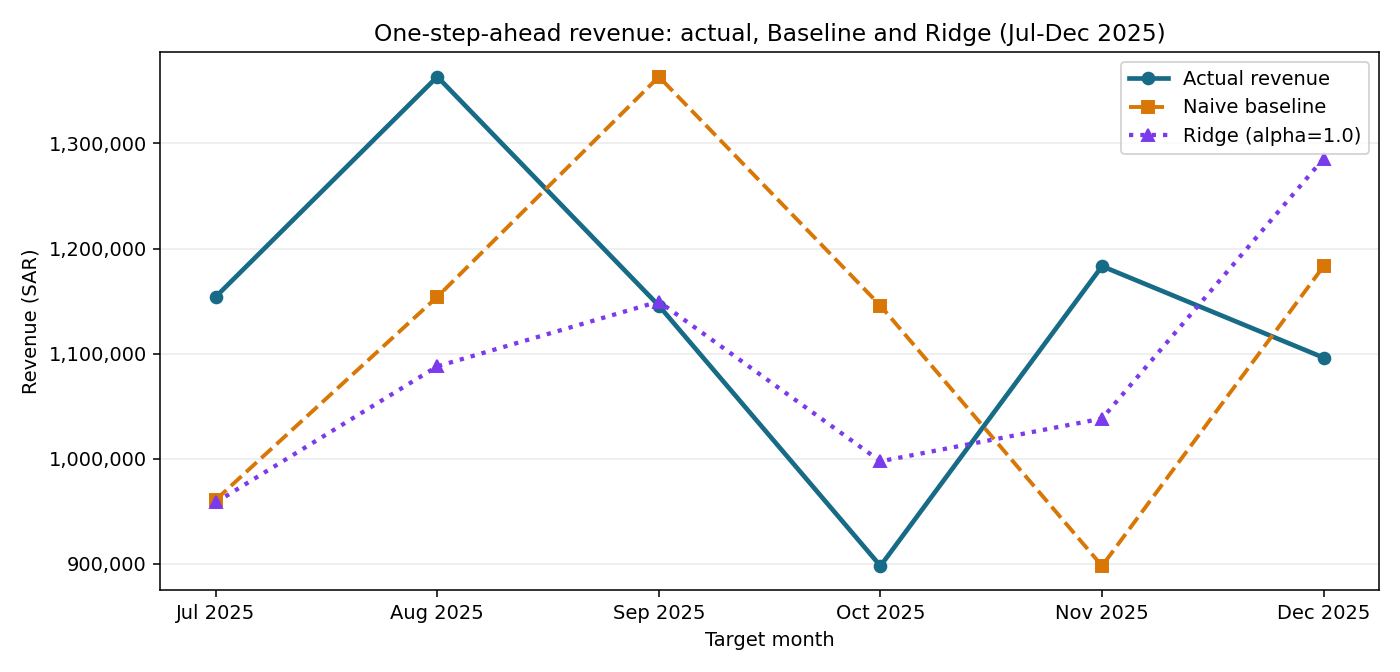

In [13]:
ridge_fig = Figure(figsize=(10, 4.8))
ridge_canvas = FigureCanvasAgg(ridge_fig)
ridge_ax = ridge_fig.subplots()
ridge_labels = ridge_results["TargetMonth"].dt.strftime("%b %Y")
ridge_ax.plot(ridge_labels, ridge_results["ActualRevenue"].map(float), color="#176b87",
              marker="o", linewidth=2.4, label="Actual revenue")
ridge_ax.plot(ridge_labels, backtest_results["BaselinePrediction"].map(float), color="#d97706",
              marker="s", linestyle="--", linewidth=2, label="Naive baseline")
ridge_ax.plot(ridge_labels, ridge_results["RidgePrediction"].map(float), color="#7c3aed",
              marker="^", linestyle=":", linewidth=2.2, label="Ridge (alpha=1.0)")
ridge_ax.set(title="One-step-ahead revenue: actual, Baseline and Ridge (Jul-Dec 2025)",
             xlabel="Target month", ylabel="Revenue (SAR)")
ridge_ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))
ridge_ax.grid(axis="y", alpha=0.25)
ridge_ax.legend()
ridge_fig.tight_layout()
with BytesIO() as ridge_chart_buffer:
    ridge_fig.savefig(ridge_chart_buffer, format="png", dpi=140)
    display(Image(data=ridge_chart_buffer.getvalue()))

## 15. Leakage, pipeline and preservation checks
Recompute Baseline from preceding-month revenue and require exact equality with Task 2 calculations. Also compare every formatted table cell and both metrics against the previously saved Task 2 outputs, copied below as display references. These references are only for validation, never model selection.

Check distinct fitted pipelines, actual fit/predict calls, training-only scaler statistics, approved training sizes, and unchanged source tables. Stop after this fixed-configuration evaluation.

In [14]:
saved_baseline_display_rows = [['2025-07', '1,154,054.68', '960,893.07', '193,161.61', '193,161.61', '37,311,408,736.76'], ['2025-08', '1,363,451.76', '1,154,054.68', '209,397.08', '209,397.08', '43,847,135,646.75'], ['2025-09', '1,145,622.91', '1,363,451.76', '-217,828.85', '217,828.85', '47,449,406,803.18'], ['2025-10', '897,984.22', '1,145,622.91', '-247,638.70', '247,638.70', '61,324,923,508.94'], ['2025-11', '1,183,186.78', '897,984.22', '285,202.57', '285,202.57', '81,340,504,223.39'], ['2025-12', '1,096,146.01', '1,183,186.78', '-87,040.77', '87,040.77', '7,576,096,425.56']]
saved_baseline_metric_display = {"MAE": "206,711.60", "RMSE": "215,580.41"}
baseline_recheck_rows = []
for month in ridge_test_months:
    previous_actual = monthly_revenue.loc[month - pd.DateOffset(months=1), "Revenue"]
    observed = monthly_revenue.loc[month, "Revenue"]
    difference = observed - previous_actual
    baseline_recheck_rows.append({"TargetMonth": month, "ActualRevenue": observed,
        "BaselinePrediction": previous_actual, "Error": difference,
        "AbsoluteError": abs(difference), "SquaredError": difference ** 2})
baseline_recheck = pd.DataFrame(baseline_recheck_rows)
pd.testing.assert_frame_equal(baseline_recheck, backtest_results, check_exact=True)
baseline_recheck_mae = exact_sum(baseline_recheck["AbsoluteError"]) / Decimal("6")
baseline_recheck_rmse = (exact_sum(baseline_recheck["SquaredError"]) / Decimal("6")).sqrt()
assert (baseline_recheck_mae, baseline_recheck_rmse) == ridge_baseline_metrics_snapshot
baseline_recheck_display = baseline_recheck.copy(deep=True)
baseline_recheck_display["TargetMonth"] = baseline_recheck_display["TargetMonth"].dt.strftime("%Y-%m")
for column in ["ActualRevenue", "BaselinePrediction", "Error", "AbsoluteError", "SquaredError"]:
    baseline_recheck_display[column] = baseline_recheck[column].map(lambda value: f"{value:,.2f}")
assert baseline_recheck_display.values.tolist() == saved_baseline_display_rows
assert f"{baseline_recheck_mae:,.2f}" == saved_baseline_metric_display["MAE"]
assert f"{baseline_recheck_rmse:,.2f}" == saved_baseline_metric_display["RMSE"]
ridge_quality_checks = {
    "Same six ordered months as Baseline": len(ridge_results) == 6
        and pd.DatetimeIndex(ridge_results["TargetMonth"]).equals(ridge_test_months),
    "Training sizes 15 through 20": ridge_results["TrainingRows"].tolist() == [15,16,17,18,19,20],
    "Training targets strictly before test month": bool((ridge_audit["TrainingEnd"] < ridge_audit["TargetMonth"]).all()),
    "Six fresh pipelines, scalers and estimators": len({id(p) for p in ridge_pipelines}) == 6
        and all(len({id(p.named_steps[s]) for p in ridge_pipelines}) == 6 for s in ["scaler", "ridge"]),
    "One real fit and predict per round": bool(ridge_audit[["FitCalls", "PredictCalls"]].eq(1).all().all()),
    "Training-only scaler verified": bool(ridge_audit["TrainingOnlyScalerChecked"].all())
        and ridge_audit["ScalerSamples"].tolist() == [15,16,17,18,19,20],
    "Fixed features and alpha=1.0": all(
        p.named_steps["scaler"].feature_names_in_.tolist() == ["lag_1", "lag_2", "lag_3"]
        and p.named_steps["ridge"].n_features_in_ == 3 and p.named_steps["ridge"].alpha == 1.0
        for p in ridge_pipelines),
    "All training and test lag sources verified": bool(ridge_audit["LagSourcesChecked"].all()),
    "No missing values": not ridge_results.isna().any().any() and not ridge_audit.isna().any().any(),
    "Finite predictions and errors": all(v.is_finite()
        for col in ["ActualRevenue","RidgePrediction","Error","AbsoluteError","SquaredError"] for v in ridge_results[col]),
    "Stored predictions equal actual predict outputs": all(
        row.RidgePrediction == Decimal.from_float(float(raw[0]))
        for row, raw in zip(ridge_results.itertuples(index=False), ridge_raw_predictions)),
    "Actual revenues match Baseline": ridge_results["ActualRevenue"].equals(backtest_results["ActualRevenue"]),
    "Baseline matches recomputation and saved outputs": True,
}
pd.testing.assert_frame_equal(feature_target, ridge_features_snapshot, check_exact=True)
pd.testing.assert_frame_equal(monthly_revenue, ridge_monthly_snapshot, check_exact=True)
pd.testing.assert_frame_equal(backtest_results, ridge_baseline_snapshot, check_exact=True)
pd.testing.assert_frame_equal(reference_checks, ridge_reference_snapshot, check_exact=True)
ridge_quality_checks["Original tables and reference metrics preserved"] = True
ridge_quality_report = pd.Series(ridge_quality_checks, name="Passed").to_frame()
display(ridge_quality_report)
assert all(ridge_quality_checks.values()), "Ridge quality check failed"
print("PASS: all Ridge checks passed. Stop here; no tuning or 2026 forecasts.")

PASS: all Ridge checks passed. Stop here; no tuning or 2026 forecasts.


,Passed
Same six ordered months as Baseline,True
Training sizes 15 through 20,True
Training targets strictly before test month,True
"Six fresh pipelines, scalers and estimators",True
One real fit and predict per round,True
Training-only scaler verified,True
Fixed features and alpha=1.0,True
All training and test lag sources verified,True
No missing values,True
Finite predictions and errors,True


## 16. Task 4: Monthly error analysis without refitting
Run this section and the following sections directly to analyze saved results; do not rerun the fitting section for this task. No model, feature, alpha, or backtesting design is changed.

If both original result tables exist in the current kernel, use deep copies at their original precision. Otherwise use the persisted Task 2/3 output snapshots below, extracted from the notebook's saved tables. Those snapshots have two decimal places; raw Ridge predictions were not persisted. The executed results in this task use those saved snapshots, so additional statistics are approximate at that precision.

Use the saved signed and absolute errors directly: they were computed before display rounding. Recomputing errors from rounded actuals/predictions can differ by 0.01 SAR. Positive ErrorReduction means Ridge has smaller absolute error. A tie is reported explicitly.

In [15]:
import pandas as pd
from decimal import Decimal, getcontext
from IPython.display import display, Image
getcontext().prec = 40
saved_error_baseline_rows = [['2025-07', '1,154,054.68', '960,893.07', '193,161.61', '193,161.61', '37,311,408,736.76'], ['2025-08', '1,363,451.76', '1,154,054.68', '209,397.08', '209,397.08', '43,847,135,646.75'], ['2025-09', '1,145,622.91', '1,363,451.76', '-217,828.85', '217,828.85', '47,449,406,803.18'], ['2025-10', '897,984.22', '1,145,622.91', '-247,638.70', '247,638.70', '61,324,923,508.94'], ['2025-11', '1,183,186.78', '897,984.22', '285,202.57', '285,202.57', '81,340,504,223.39'], ['2025-12', '1,096,146.01', '1,183,186.78', '-87,040.77', '87,040.77', '7,576,096,425.56']]
saved_error_ridge_rows = [['2025-07', '15', '1,154,054.68', '958,426.12', '195,628.57', '195,628.57', '38,270,535,724.08'], ['2025-08', '16', '1,363,451.76', '1,087,908.88', '275,542.88', '275,542.88', '75,923,880,219.81'], ['2025-09', '17', '1,145,622.91', '1,149,583.65', '-3,960.74', '3,960.74', '15,687,464.93'], ['2025-10', '18', '897,984.22', '997,543.37', '-99,559.16', '99,559.16', '9,912,025,432.66'], ['2025-11', '19', '1,183,186.78', '1,038,217.59', '144,969.19', '144,969.19', '21,016,067,225.82'], ['2025-12', '20', '1,096,146.01', '1,285,588.27', '-189,442.26', '189,442.26', '35,888,368,274.99']]
base_error_columns = ["TargetMonth", "ActualRevenue", "BaselinePrediction", "Error", "AbsoluteError", "SquaredError"]
ridge_error_columns = ["TargetMonth", "TrainingRows", "ActualRevenue", "RidgePrediction", "Error", "AbsoluteError", "SquaredError"]
def restore_error_snapshot(rows, columns):
    table = pd.DataFrame(rows, columns=columns)
    table["TargetMonth"] = pd.to_datetime(table["TargetMonth"], format="%Y-%m")
    for column in columns:
        if column == "TargetMonth":
            continue
        table[column] = table[column].map(lambda text: Decimal(text.replace(",", "")))
    return table

if "backtest_results" in globals() and "ridge_results" in globals():
    error_base_source = backtest_results.copy(deep=True)
    error_ridge_source = ridge_results.copy(deep=True)
    error_source_mode = "Original in-memory results (unrounded)"
else:
    error_base_source = restore_error_snapshot(saved_error_baseline_rows, base_error_columns)
    error_ridge_source = restore_error_snapshot(saved_error_ridge_rows, ridge_error_columns)
    error_source_mode = "Saved notebook outputs (two-decimal precision; no refitting)"
print("Analysis source:", error_source_mode)
error_base_snapshot = error_base_source.copy(deep=True)
error_ridge_snapshot = error_ridge_source.copy(deep=True)
error_expected_months = pd.date_range("2025-07-01", "2025-12-01", freq="MS")
for source in (error_base_source, error_ridge_source):
    assert pd.DatetimeIndex(source["TargetMonth"]).equals(error_expected_months)
    assert not source.isna().any().any()
    assert source["TargetMonth"].is_unique
    assert all(isinstance(value, Decimal) and value.is_finite()
               for column in ["ActualRevenue", "Error", "AbsoluteError", "SquaredError"] for value in source[column])
    assert all(abs(e) == a for e, a in zip(source["Error"], source["AbsoluteError"]))
assert error_base_source["ActualRevenue"].equals(error_ridge_source["ActualRevenue"])

def error_sum(values):
    return sum(values, Decimal("0"))

def error_display(table):
    shown = table.copy(deep=True)
    for column in shown.columns:
        if column == "TargetMonth":
            shown[column] = shown[column].dt.strftime("%Y-%m")
        elif shown[column].map(lambda value: isinstance(value, Decimal)).all():
            shown[column] = shown[column].map(lambda value: f"{value:,.2f}")
    return shown

Analysis source: Saved notebook outputs (two-decimal precision; no refitting)


## 17. Monthly absolute-error comparison
ErrorReduction = BaselineAbsoluteError - RidgeAbsoluteError. Positive favors Ridge, negative favors Baseline. These are paired errors for exactly the same target months.

In [16]:
monthly_error_comparison = error_base_source[["TargetMonth", "ActualRevenue", "BaselinePrediction", "AbsoluteError"]].rename(
    columns={"AbsoluteError": "BaselineAbsoluteError"}
).merge(
    error_ridge_source[["TargetMonth", "RidgePrediction", "AbsoluteError"]].rename(columns={"AbsoluteError": "RidgeAbsoluteError"}),
    on="TargetMonth", how="inner", validate="one_to_one"
)
monthly_error_comparison = monthly_error_comparison[[
    "TargetMonth", "ActualRevenue", "BaselinePrediction", "RidgePrediction", "BaselineAbsoluteError", "RidgeAbsoluteError"
]]
monthly_error_comparison["ErrorReduction"] = (
    monthly_error_comparison["BaselineAbsoluteError"] - monthly_error_comparison["RidgeAbsoluteError"]
)
monthly_error_comparison["BetterModel"] = monthly_error_comparison["ErrorReduction"].map(
    lambda value: "Ridge" if value > 0 else "Baseline" if value < 0 else "Tie"
)
display(error_display(monthly_error_comparison))

,TargetMonth,ActualRevenue,BaselinePrediction,RidgePrediction,BaselineAbsoluteError,RidgeAbsoluteError,ErrorReduction,BetterModel
0,2025-07,"1,154,054.68","960,893.07","958,426.12","193,161.61","195,628.57","-2,466.96",Baseline
1,2025-08,"1,363,451.76","1,154,054.68","1,087,908.88","209,397.08","275,542.88","-66,145.80",Baseline
2,2025-09,"1,145,622.91","1,363,451.76","1,149,583.65","217,828.85","3,960.74","213,868.11",Ridge
3,2025-10,"897,984.22","1,145,622.91","997,543.37","247,638.70","99,559.16","148,079.54",Ridge
4,2025-11,"1,183,186.78","897,984.22","1,038,217.59","285,202.57","144,969.19","140,233.38",Ridge
5,2025-12,"1,096,146.01","1,183,186.78","1,285,588.27","87,040.77","189,442.26","-102,401.49",Baseline


## 18. Stability, signed bias and concentration
Mean Error uses Actual - Prediction: positive means average underprediction; negative means average overprediction. Signed errors can cancel, so Mean Error is not a substitute for MAE/RMSE. Report directional counts separately.

Each monthly absolute-error contribution is that month's absolute error divided by its model's total absolute error. Contribution to the net Ridge gain is signed and can exceed 100% or be negative because improved and worsened months offset each other. Zero denominators are explicitly guarded.

In [17]:
ridge_wins = int(monthly_error_comparison["BetterModel"].eq("Ridge").sum())
baseline_wins = int(monthly_error_comparison["BetterModel"].eq("Baseline").sum())
error_ties = int(monthly_error_comparison["BetterModel"].eq("Tie").sum())
best_reduction = max(monthly_error_comparison["ErrorReduction"])
worst_reduction = min(monthly_error_comparison["ErrorReduction"])
best_reduction_rows = monthly_error_comparison.loc[monthly_error_comparison["ErrorReduction"].eq(best_reduction)]
worst_reduction_rows = monthly_error_comparison.loc[monthly_error_comparison["ErrorReduction"].eq(worst_reduction)]
error_bias_rows = []
for name, source in [("Baseline", error_base_source), ("Ridge", error_ridge_source)]:
    error_bias_rows.append({"Model": name, "MeanError": error_sum(source["Error"]) / Decimal(len(source)),
        "OverpredictionMonths": int((source["Error"] < 0).sum()),
        "UnderpredictionMonths": int((source["Error"] > 0).sum()),
        "ExactMonths": int(source["Error"].eq(0).sum())})
error_bias = pd.DataFrame(error_bias_rows)
error_contributions = monthly_error_comparison[["TargetMonth", "BaselineAbsoluteError", "RidgeAbsoluteError", "ErrorReduction"]].copy(deep=True)
base_total_absolute = error_sum(error_contributions["BaselineAbsoluteError"])
ridge_total_absolute = error_sum(error_contributions["RidgeAbsoluteError"])
net_absolute_gain = base_total_absolute - ridge_total_absolute
assert base_total_absolute > 0 and ridge_total_absolute > 0
error_contributions["BaselineSharePct"] = error_contributions["BaselineAbsoluteError"].map(lambda value: value / base_total_absolute * Decimal("100"))
error_contributions["RidgeSharePct"] = error_contributions["RidgeAbsoluteError"].map(lambda value: value / ridge_total_absolute * Decimal("100"))
error_contributions["NetGainSharePct"] = error_contributions["ErrorReduction"].map(
    lambda value: value / net_absolute_gain * Decimal("100") if net_absolute_gain != 0 else None
)
positive_gain = error_sum(monthly_error_comparison.loc[monthly_error_comparison["ErrorReduction"] > 0, "ErrorReduction"])
negative_gain = error_sum(monthly_error_comparison.loc[monthly_error_comparison["ErrorReduction"] < 0, "ErrorReduction"])
print("Ridge wins:", ridge_wins, "Baseline wins:", baseline_wins, "Ties:", error_ties)
print("Largest Ridge improvement:", ", ".join(best_reduction_rows["TargetMonth"].dt.strftime("%Y-%m")), f"{best_reduction:,.2f} SAR")
print("Largest Ridge deterioration:", ", ".join(worst_reduction_rows["TargetMonth"].dt.strftime("%Y-%m")), f"{-worst_reduction:,.2f} SAR")
print(f"Total absolute errors: Baseline {base_total_absolute:,.2f}; Ridge {ridge_total_absolute:,.2f} SAR")
print(f"Gross gains: {positive_gain:,.2f}; offsetting losses: {-negative_gain:,.2f}; net gain: {net_absolute_gain:,.2f} SAR")
display(error_display(error_bias))
display(error_display(error_contributions))

Ridge wins: 3 Baseline wins: 3 Ties: 0
Largest Ridge improvement: 2025-09 213,868.11 SAR
Largest Ridge deterioration: 2025-12 102,401.49 SAR
Total absolute errors: Baseline 1,240,269.58; Ridge 909,102.80 SAR
Gross gains: 502,181.03; offsetting losses: 171,014.25; net gain: 331,166.78 SAR


,Model,MeanError,OverpredictionMonths,UnderpredictionMonths,ExactMonths
0,Baseline,"22,542.16",3,3,0
1,Ridge,"53,863.08",3,3,0


,TargetMonth,BaselineAbsoluteError,RidgeAbsoluteError,ErrorReduction,BaselineSharePct,RidgeSharePct,NetGainSharePct
0,2025-07,"193,161.61","195,628.57","-2,466.96",15.57,21.52,-0.74
1,2025-08,"209,397.08","275,542.88","-66,145.80",16.88,30.31,-19.97
2,2025-09,"217,828.85","3,960.74","213,868.11",17.56,0.44,64.58
3,2025-10,"247,638.70","99,559.16","148,079.54",19.97,10.95,44.71
4,2025-11,"285,202.57","144,969.19","140,233.38",23.00,15.95,42.35
5,2025-12,"87,040.77","189,442.26","-102,401.49",7.02,20.84,-30.92


## 19. Monthly error reduction chart
Positive bars mean improvement with Ridge; negative bars mean deterioration. The zero reference, signs and labels make the direction explicit. Previous charts are preserved. Only chart coordinates are converted to float.

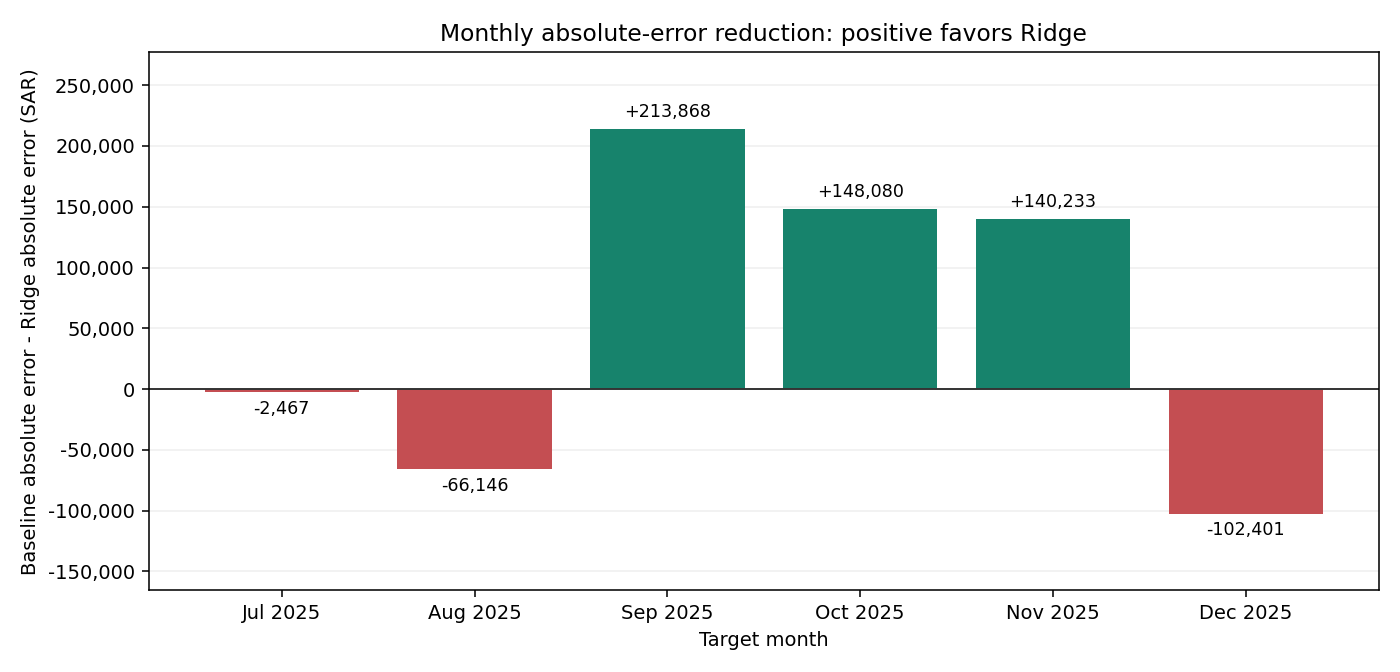

In [18]:
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.ticker import FuncFormatter
from io import BytesIO
error_fig = Figure(figsize=(10, 4.8))
error_canvas = FigureCanvasAgg(error_fig)
error_ax = error_fig.subplots()
error_plot_values = monthly_error_comparison["ErrorReduction"].map(float)
error_bars = error_ax.bar(monthly_error_comparison["TargetMonth"].dt.strftime("%b %Y"), error_plot_values,
    color=["#17836c" if value >= 0 else "#c44e52" for value in error_plot_values])
error_ax.axhline(0, color="#333333", linewidth=1)
error_ax.bar_label(error_bars, labels=[f"{value:+,.0f}" for value in error_plot_values], padding=4, fontsize=9)
error_ax.set(title="Monthly absolute-error reduction: positive favors Ridge",
             xlabel="Target month", ylabel="Baseline absolute error - Ridge absolute error (SAR)")
error_ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))
error_ax.margins(y=0.20)
error_ax.grid(axis="y", alpha=0.2)
error_ax.set_axisbelow(True)
error_fig.tight_layout()
with BytesIO() as error_chart_buffer:
    error_fig.savefig(error_chart_buffer, format="png", dpi=140)
    display(Image(data=error_chart_buffer.getvalue()))

## 20. Error-analysis quality checks
Check exact calendar alignment, signed-error direction counts, contribution totals, and the identity between aggregate error reduction and the difference in MAE. Compare rounded metrics to the saved evaluation with 0.01 SAR tolerance because persisted table entries were individually rounded. Do not overwrite prior metrics or tables.

In [19]:
analysis_mae_baseline = base_total_absolute / Decimal("6")
analysis_mae_ridge = ridge_total_absolute / Decimal("6")
analysis_rmse_baseline = (error_sum(error_base_source["SquaredError"]) / Decimal("6")).sqrt()
analysis_rmse_ridge = (error_sum(error_ridge_source["SquaredError"]) / Decimal("6")).sqrt()
for current, reference in [(analysis_mae_baseline, "206711.60"), (analysis_mae_ridge, "151517.13"),
                           (analysis_rmse_baseline, "215580.41"), (analysis_rmse_ridge, "173698.28")]:
    assert abs(current - Decimal(reference)) <= Decimal("0.01")
assert len(monthly_error_comparison) == 6
assert pd.DatetimeIndex(monthly_error_comparison["TargetMonth"]).equals(error_expected_months)
assert not monthly_error_comparison.isna().any().any()
assert ridge_wins + baseline_wins + error_ties == 6
assert all(row.OverpredictionMonths + row.UnderpredictionMonths + row.ExactMonths == 6 for row in error_bias.itertuples(index=False))
for column in ["BaselineSharePct", "RidgeSharePct"]:
    assert abs(error_sum(error_contributions[column]) - Decimal("100")) < Decimal("1e-30")
if net_absolute_gain != 0:
    assert abs(error_sum(error_contributions["NetGainSharePct"]) - Decimal("100")) < Decimal("1e-30")
assert error_sum(monthly_error_comparison["ErrorReduction"]) == net_absolute_gain
assert abs(net_absolute_gain / Decimal("6") - (analysis_mae_baseline - analysis_mae_ridge)) < Decimal("1e-30")
pd.testing.assert_frame_equal(error_base_source, error_base_snapshot, check_exact=True)
pd.testing.assert_frame_equal(error_ridge_source, error_ridge_snapshot, check_exact=True)
if "backtest_results" in globals() and "ridge_results" in globals():
    pd.testing.assert_frame_equal(backtest_results, error_base_source, check_exact=True)
    pd.testing.assert_frame_equal(ridge_results, error_ridge_source, check_exact=True)
print("PASS: saved metrics consistent, aligned months, contribution totals, bias counts, original results preserved.")
print("No model fitting, predictions, tuning, data loading, or external file output in this analysis.")

PASS: saved metrics consistent, aligned months, contribution totals, bias counts, original results preserved.
No model fitting, predictions, tuning, data loading, or external file output in this analysis.


## 21. Interpretation: measured findings and limits

### Computed findings
- Ridge has lower overall errors on this six-month evaluation: saved MAE 151,517.13 versus 206,711.60 SAR; saved RMSE 173,698.28 versus 215,580.41 SAR (26.70% and 19.43% lower respectively).
- Ridge wins **3 of 6 months**, exactly half, not a majority: September, October and November. Baseline wins July, August and December; there are no ties.
- Largest Ridge improvement: September, **213,868.11 SAR**. Largest deterioration: December, **102,401.49 SAR**.
- September-November supply **502,181.03 SAR** of gross absolute-error reduction. Losses in July, August and December offset **171,014.25 SAR**, leaving **331,166.78 SAR** net reduction. September is the largest contributor; October and November also materially contribute. Winning improvements outweigh losing deterioration even though the monthly win count is tied.
- Baseline Mean Error: **22,542.16 SAR**; Ridge: **53,863.08 SAR**. Both are positive (average underprediction). Both overpredict in 3 months and underpredict in 3 months; neither direction dominates by count. Directional magnitudes, not frequency, explain positive average bias. Ridge's positive mean error is larger despite lower MAE/RMSE.
- Ridge's two largest absolute-error contributions are August and July, together **51.83%** of its total. Baseline's two largest are November and October, together **42.96%**. The monthly contribution table shows concentration rather than uniform performance.

### Interpretation and limitations
Ridge is better in aggregate on this window, but not uniformly or in a majority of months. Its advantage is concentrated in September-November and partly offset elsewhere; the six-month aggregate alone hides this variation. These are observed error patterns, not evidence of a particular commercial or seasonal cause.

Only 24 historical months and six held-out months are available. With three lags, there are 21 usable rows, and the six models trained on only 15-20 rows each. The holdout covers only July-December 2025, not a full annual cycle or multiple independent years. Expanding windows overlap heavily; six errors are too few to establish stable generalization, persistent bias, or statistical superiority.

Possible explanations for error variation remain untested. This analysis cannot attribute the changes to promotions, demand shifts, seasonality or any other business mechanism. No such cause is assumed, and the evaluation is not used to modify the model.

Lower historical errors do not guarantee future reliability: future patterns may differ, this test is small, and it evaluates one-step-ahead forecasts that receive the previous month's actual before the next prediction. It does not validate recursive multi-month forecasting or provide calibrated prediction intervals. No 2026 forecast or design change follows.

Precision note: this executed analysis reads saved two-decimal result tables without refitting. Minor differences of about a cent can arise from display rounding; original results and saved aggregate metrics remain unchanged.

## Experimental One-Step-Ahead Forecast — January 2026

This forecast is **experimental and educational**. The historical data are synthetic and end in December 2025. January 2026 is outside the original generated dataset, and the project contains no corresponding actual revenue with which to measure this forecast's error. Historical MAE and RMSE must not be interpreted as a guarantee of this forecast's accuracy or as a prediction interval.

Fit one new Pipeline using StandardScaler with its original defaults and Ridge(alpha=1.0), on all 21 valid historical rows (April 2024–December 2025). The three features are unchanged. Forecast only January 2026 from the exact observed revenue of December, November and October 2025. Do not use rounded display snapshots or any 2026 actuals.

The previous backtesting results remain independent and unchanged: this final full-history fit does not replace any evaluation model or revise its scores. No tuning, additional forecast month, synthetic future observation, CSV export, or model serialization is performed.

Execution: run the original preparation sections 1–6 if their variables are not available, then this section. The backtesting and error-analysis sections do not need to be rerun.

In [20]:
import numpy as np
import sklearn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from unittest.mock import patch

print("scikit-learn version:", sklearn.__version__)
JAN2026_FEATURES = ["lag_1", "lag_2", "lag_3"]
jan2026_month = pd.Timestamp("2026-01-01")
jan2026_cutoff = pd.Timestamp("2025-12-01")
jan2026_monthly_snapshot = monthly_revenue.copy(deep=True)
jan2026_features_snapshot = feature_target.copy(deep=True)
jan2026_reference_snapshot = reference_checks.copy(deep=True)
# If earlier evaluation tables are in memory, explicitly verify their preservation.
jan2026_prior_table_snapshots = {
    name: globals()[name].copy(deep=True)
    for name in ["backtest_results", "ridge_results", "comparison_results", "monthly_error_comparison", "error_bias"]
    if name in globals()
}
jan2026_prior_metric_snapshots = {
    name: globals()[name] for name in ["baseline_mae", "baseline_rmse", "ridge_mae", "ridge_rmse"]
    if name in globals()
}
assert sklearn.__version__ == "1.7.2", "Reproduce the approved environment before executing."
assert monthly_revenue.index.equals(pd.date_range("2024-01-01", jan2026_cutoff, freq="MS", name="Month"))
assert jan2026_month not in monthly_revenue.index
assert orders["OrderDate"].max() < jan2026_month, "Unexpected future actuals in the source orders"
jan2026_training = feature_target.loc[feature_target["TargetMonth"] < jan2026_month].copy(deep=True)
assert len(jan2026_training) == len(feature_target) == 21
assert pd.DatetimeIndex(jan2026_training["TargetMonth"]).equals(
    pd.date_range("2024-04-01", jan2026_cutoff, freq="MS")
)
assert jan2026_training["TargetMonth"].is_unique
assert not jan2026_training[[*JAN2026_FEATURES, "Target"]].isna().any().any()
for row in jan2026_training.itertuples(index=False):
    assert row.TargetMonth < jan2026_month
    assert row.Target == monthly_revenue.loc[row.TargetMonth, "Revenue"]
    for offset in (1, 2, 3):
        source_month = row.TargetMonth - pd.DateOffset(months=offset)
        assert source_month < row.TargetMonth
        assert getattr(row, f"lag_{offset}") == monthly_revenue.loc[source_month, "Revenue"]

jan2026_input_exact = pd.DataFrame([{
    f"lag_{offset}": monthly_revenue.loc[jan2026_month - pd.DateOffset(months=offset), "Revenue"]
    for offset in (1, 2, 3)
}], columns=JAN2026_FEATURES)
jan2026_feature_sources = pd.DataFrame([
    {"Feature": f"lag_{offset}", "SourceMonth": jan2026_month - pd.DateOffset(months=offset),
     "ExactRevenue": jan2026_input_exact.loc[0, f"lag_{offset}"]}
    for offset in (1, 2, 3)
])
assert jan2026_input_exact.columns.tolist() == JAN2026_FEATURES
assert (jan2026_feature_sources["SourceMonth"] < jan2026_month).all()
assert all(isinstance(v, Decimal) and v.is_finite() for v in jan2026_input_exact.iloc[0])
print("Final training rows:", len(jan2026_training))
print("Training target period:", jan2026_training["TargetMonth"].min(), "through", jan2026_training["TargetMonth"].max())
print("Exact feature values (no rounding)")
display(jan2026_feature_sources)

scikit-learn version: 1.7.2
Final training rows: 21
Training target period: 2024-04-01 00:00:00 through 2025-12-01 00:00:00
Exact feature values (no rounding)


,Feature,SourceMonth,ExactRevenue
0,lag_1,2025-12-01,1096146.0100
1,lag_2,2025-11-01,1183186.7845
2,lag_3,2025-10-01,897984.2175


In [21]:
jan2026_X_train = jan2026_training[JAN2026_FEATURES].astype(np.float64)
jan2026_y_train = jan2026_training["Target"].to_numpy(dtype=np.float64)
jan2026_X_input = jan2026_input_exact.astype(np.float64)
assert jan2026_X_train.columns.tolist() == jan2026_X_input.columns.tolist() == JAN2026_FEATURES
for matrix in (jan2026_X_train.to_numpy(), jan2026_y_train, jan2026_X_input.to_numpy()):
    assert matrix.dtype == np.float64 and np.isfinite(matrix).all()
assert jan2026_X_input.shape == (1, 3)

jan2026_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0)),
])
assert not hasattr(jan2026_pipeline.named_steps["scaler"], "mean_")
assert not hasattr(jan2026_pipeline.named_steps["ridge"], "coef_")
if "ridge_pipelines" in globals():
    assert all(jan2026_pipeline is not prior for prior in ridge_pipelines)
with patch.object(jan2026_pipeline, "fit", wraps=jan2026_pipeline.fit) as jan2026_fit_call:
    jan2026_pipeline.fit(jan2026_X_train, jan2026_y_train)
    jan2026_fit_count = jan2026_fit_call.call_count
    assert jan2026_fit_call.call_args.args[0] is jan2026_X_train
    assert jan2026_fit_call.call_args.args[1] is jan2026_y_train
assert jan2026_fit_count == 1
jan2026_scaler = jan2026_pipeline.named_steps["scaler"]
assert jan2026_scaler.n_samples_seen_ == 21
assert jan2026_scaler.with_mean and jan2026_scaler.with_std and jan2026_scaler.copy
assert jan2026_scaler.feature_names_in_.tolist() == JAN2026_FEATURES
np.testing.assert_allclose(jan2026_scaler.mean_, jan2026_X_train.to_numpy().mean(axis=0), rtol=1e-12, atol=1e-9)
np.testing.assert_allclose(jan2026_scaler.var_, jan2026_X_train.to_numpy().var(axis=0), rtol=1e-12, atol=1e-9)
assert jan2026_pipeline.named_steps["ridge"].get_params() == Ridge(alpha=1.0).get_params()
jan2026_scaler_state = (jan2026_scaler.mean_.copy(), jan2026_scaler.var_.copy(), jan2026_scaler.scale_.copy())
with patch.object(jan2026_pipeline, "predict", wraps=jan2026_pipeline.predict) as jan2026_predict_call:
    jan2026_raw_prediction = jan2026_pipeline.predict(jan2026_X_input)
    jan2026_predict_count = jan2026_predict_call.call_count
    assert jan2026_predict_call.call_args.args[0] is jan2026_X_input
assert jan2026_predict_count == 1
assert jan2026_raw_prediction.shape == (1,) and np.isfinite(jan2026_raw_prediction).all()
for current, prior in zip((jan2026_scaler.mean_, jan2026_scaler.var_, jan2026_scaler.scale_), jan2026_scaler_state):
    np.testing.assert_array_equal(current, prior)
assert jan2026_scaler.n_samples_seen_ == 21

jan2026_ridge_prediction = Decimal.from_float(float(jan2026_raw_prediction[0]))
jan2026_baseline_prediction = monthly_revenue.loc[jan2026_cutoff, "Revenue"]
jan2026_prediction_difference = jan2026_ridge_prediction - jan2026_baseline_prediction
jan2026_forecast_results = pd.DataFrame([{
    "TargetMonth": jan2026_month, "TrainingRows": len(jan2026_training),
    "RidgePrediction": jan2026_ridge_prediction, "BaselinePrediction": jan2026_baseline_prediction,
    "Difference (Ridge - Baseline)": jan2026_prediction_difference,
}])
jan2026_forecast_display = jan2026_forecast_results.copy(deep=True)
jan2026_forecast_display["TargetMonth"] = jan2026_forecast_display["TargetMonth"].dt.strftime("%Y-%m")
for column in ["RidgePrediction", "BaselinePrediction", "Difference (Ridge - Baseline)"]:
    jan2026_forecast_display[column] = jan2026_forecast_results[column].map(lambda v: f"{v:,.2f}")
display(jan2026_forecast_display)
print(f"Experimental Ridge forecast: {jan2026_ridge_prediction:,.2f} SAR")
print(f"Naive Baseline forecast: {jan2026_baseline_prediction:,.2f} SAR")
print(f"Difference (Ridge - Baseline): {jan2026_prediction_difference:+,.2f} SAR")
# Persist a lossless forecast snapshot in notebook output, not in an extra file.
print("Unrounded Ridge predict() float64 value:", repr(float(jan2026_raw_prediction[0])))
print("Exact Baseline value:", str(jan2026_baseline_prediction))

Experimental Ridge forecast: 948,120.11 SAR
Naive Baseline forecast: 1,096,146.01 SAR
Difference (Ridge - Baseline): -148,025.90 SAR
Unrounded Ridge predict() float64 value: 948120.1066415942
Exact Baseline value: 1096146.0100


,TargetMonth,TrainingRows,RidgePrediction,BaselinePrediction,Difference (Ridge - Baseline)
0,2026-01,21,"948,120.11","1,096,146.01","-148,025.90"


In [22]:
pd.testing.assert_frame_equal(monthly_revenue, jan2026_monthly_snapshot, check_exact=True)
pd.testing.assert_frame_equal(feature_target, jan2026_features_snapshot, check_exact=True)
pd.testing.assert_frame_equal(reference_checks, jan2026_reference_snapshot, check_exact=True)
for name, prior in jan2026_prior_table_snapshots.items():
    pd.testing.assert_frame_equal(globals()[name], prior, check_exact=True)
for name, prior in jan2026_prior_metric_snapshots.items():
    assert globals()[name] == prior
jan2026_quality = pd.Series({
    "All 21 historical training rows, April-December across 2024-2025": len(jan2026_training) == 21,
    "Training ends December 2025; no future target": jan2026_training["TargetMonth"].max() == jan2026_cutoff,
    "Exact source months December, November, October 2025": jan2026_feature_sources["SourceMonth"].tolist()
        == [pd.Timestamp("2025-12-01"), pd.Timestamp("2025-11-01"), pd.Timestamp("2025-10-01")],
    "Column names and order match training": jan2026_X_input.columns.equals(jan2026_X_train.columns),
    "StandardScaler defaults and Ridge(alpha=1.0) unchanged":
        jan2026_pipeline.named_steps["scaler"].get_params() == StandardScaler().get_params()
        and jan2026_pipeline.named_steps["ridge"].get_params() == Ridge(alpha=1.0).get_params(),
    "Scaler trained on 21 historical rows only": int(jan2026_scaler.n_samples_seen_) == 21,
    "One actual fit and one predict call": jan2026_fit_count == jan2026_predict_count == 1,
    "Exactly one forecast month, January 2026": len(jan2026_forecast_results) == 1
        and jan2026_forecast_results.loc[0, "TargetMonth"] == jan2026_month,
    "No NaN or Infinity after conversion or prediction": all(np.isfinite(v).all() for v in
        [jan2026_X_train.to_numpy(), jan2026_y_train, jan2026_X_input.to_numpy(), jan2026_raw_prediction]),
    "Baseline equals exact December actual": jan2026_baseline_prediction == jan2026_input_exact.loc[0, "lag_1"],
    "Historical tables and available evaluation results unchanged": True,
}, name="Passed").to_frame()
display(jan2026_quality)
assert jan2026_quality["Passed"].all()
print("PASS: final-fit and input checks passed. No actual January outcome exists to score this forecast.")
print("Stop after this experimental January forecast; no final report or additional month.")

PASS: final-fit and input checks passed. No actual January outcome exists to score this forecast.
Stop after this experimental January forecast; no final report or additional month.


,Passed
"All 21 historical training rows, April-December across 2024-2025",True
Training ends December 2025; no future target,True
"Exact source months December, November, October 2025",True
Column names and order match training,True
StandardScaler defaults and Ridge(alpha=1.0) unchanged,True
Scaler trained on 21 historical rows only,True
One actual fit and one predict call,True
"Exactly one forecast month, January 2026",True
No NaN or Infinity after conversion or prediction,True
Baseline equals exact December actual,True
